# Lab | Data Structuring and Combining Data

## Challenge 1: Combining & Cleaning Data

In this challenge, we will be working with the customer data from an insurance company, as we did in the two previous labs. The data can be found here:
- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file1.csv

But this time, we got new data, which can be found in the following 2 CSV files located at the links below.

- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file2.csv
- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file3.csv

Note that you'll need to clean and format the new data.

Observation:
- One option is to first combine the three datasets and then apply the cleaning function to the new combined dataset
- Another option would be to read the clean file you saved in the previous lab, and just clean the two new files and concatenate the three clean datasets

In [2]:
import pandas as pd

url1 = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file1.csv"
url2 = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file2.csv"
url3 = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file3.csv"

def load_and_standardize(url):
    df = pd.read_csv(url)
    # Nombres de columnas: minúsculas, sin espacios
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
    # file1 y file2 usan "st", file3 usa "state"
    return df.rename(columns={"st": "state"})

df1 = load_and_standardize(url1)
df2 = load_and_standardize(url2)
df3 = load_and_standardize(url3)

print(df1.shape, df2.shape, df3.shape)

(4008, 11) (996, 11) (7070, 11)


In [3]:
# Las columnas están en distinto orden, pero concat alinea por nombre
df = pd.concat([df1, df2, df3], ignore_index=True)
print(df.shape)
df.head()

(12074, 11)


,customer,state,gender,education,customer_lifetime_value,income,monthly_premium_auto,number_of_open_complaints,policy_type,vehicle_class,total_claim_amount
0,RB50392,Washington,NaN,Master,NaN,0.0,1000.0,1/0/00,Personal Auto,Four-Door Car,2.704934
1,QZ44356,Arizona,F,Bachelor,697953.59%,0.0,94.0,1/0/00,Personal Auto,Four-Door Car,1131.464935
2,AI49188,Nevada,F,Bachelor,1288743.17%,48767.0,108.0,1/0/00,Personal Auto,Two-Door Car,566.472247
3,WW63253,California,M,Bachelor,764586.18%,0.0,106.0,1/0/00,Corporate Auto,SUV,529.881344
4,GA49547,Washington,M,High School or Below,536307.65%,36357.0,68.0,1/0/00,Personal Auto,Four-Door Car,17.269323


# Challenge 2: Structuring Data

In this challenge, we will continue to work with customer data from an insurance company, but we will use a dataset with more columns, called marketing_customer_analysis.csv, which can be found at the following link:

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv

This dataset contains information such as customer demographics, policy details, vehicle information, and the customer's response to the last marketing campaign. Our goal is to explore and analyze this data by performing data cleaning, formatting, and structuring.

In [6]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(10910, 27)


,unnamed:_0,customer,state,customer_lifetime_value,response,coverage,education,effective_to_date,employmentstatus,gender,...,number_of_policies,policy_type,policy,renew_offer_type,sales_channel,total_claim_amount,vehicle_class,vehicle_size,vehicle_type,month
0,0,DK49336,Arizona,4809.216960,No,Basic,College,2011-02-18,Employed,M,...,9,Corporate Auto,Corporate L3,Offer3,Agent,292.800000,Four-Door Car,Medsize,A,2
1,1,KX64629,California,2228.525238,No,Basic,College,2011-01-18,Unemployed,F,...,1,Personal Auto,Personal L3,Offer4,Call Center,744.924331,Four-Door Car,Medsize,A,1
2,2,LZ68649,Washington,14947.917300,No,Basic,Bachelor,2011-02-10,Employed,M,...,2,Personal Auto,Personal L3,Offer3,Call Center,480.000000,SUV,Medsize,A,2
3,3,XL78013,Oregon,22332.439460,Yes,Extended,College,2011-01-11,Employed,M,...,2,Corporate Auto,Corporate L3,Offer2,Branch,484.013411,Four-Door Car,Medsize,A,1
4,4,QA50777,Oregon,9025.067525,No,Premium,Bachelor,2011-01-17,Medical Leave,F,...,7,Personal Auto,Personal L2,Offer1,Branch,707.925645,Four-Door Car,Medsize,A,1


In [7]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 10910 entries, 0 to 10909
Data columns (total 27 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   unnamed:_0                     10910 non-null  int64  
 1   customer                       10910 non-null  str    
 2   state                          10910 non-null  str    
 3   customer_lifetime_value        10910 non-null  float64
 4   response                       10910 non-null  str    
 5   coverage                       10910 non-null  str    
 6   education                      10910 non-null  str    
 7   effective_to_date              10910 non-null  str    
 8   employmentstatus               10910 non-null  str    
 9   gender                         10910 non-null  str    
 10  income                         10910 non-null  int64  
 11  location_code                  10910 non-null  str    
 12  marital_status                 10910 non-null  str    
 1

,unnamed:_0,customer_lifetime_value,income,monthly_premium_auto,months_since_last_claim,months_since_policy_inception,number_of_open_complaints,number_of_policies,total_claim_amount,month
count,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000,10910.000000
mean,5454.500000,8018.241094,37536.284785,93.196059,15.149071,48.091934,0.384256,2.979193,434.888330,1.466728
std,3149.590053,6885.081434,30359.195670,34.442532,9.783520,27.940675,0.885589,2.399359,292.180556,0.498915
min,0.000000,1898.007675,0.000000,61.000000,0.000000,0.000000,0.000000,1.000000,0.099007,1.000000
25%,2727.250000,4014.453113,0.000000,68.000000,7.000000,24.000000,0.000000,1.000000,271.082527,1.000000
50%,5454.500000,5771.147235,33813.500000,83.000000,15.000000,48.000000,0.000000,2.000000,382.564630,1.000000
75%,8181.750000,8992.779137,62250.750000,109.000000,23.000000,71.000000,0.384256,4.000000,547.200000,2.000000
max,10909.000000,83325.381190,99981.000000,298.000000,35.000000,99.000000,5.000000,9.000000,2893.239678,2.000000


In [8]:
high_claim_responders = df[(df["total_claim_amount"] > 1000) & (df["response"] == "Yes")]

print(high_claim_responders.shape)
high_claim_responders.head()

(67, 27)


,unnamed:_0,customer,state,customer_lifetime_value,response,coverage,education,effective_to_date,employmentstatus,gender,...,number_of_policies,policy_type,policy,renew_offer_type,sales_channel,total_claim_amount,vehicle_class,vehicle_size,vehicle_type,month
189,189,OK31456,California,11009.130490,Yes,Premium,Bachelor,2011-01-24,Employed,F,...,1,Corporate Auto,Corporate L3,Offer2,Agent,1358.400000,Luxury Car,Medsize,A,1
236,236,YJ16163,Oregon,11009.130490,Yes,Premium,Bachelor,2011-01-24,Employed,F,...,1,Special Auto,Special L3,Offer2,Agent,1358.400000,Luxury Car,Medsize,A,1
419,419,GW43195,Oregon,25807.063000,Yes,Extended,College,2011-02-13,Employed,F,...,2,Personal Auto,Personal L2,Offer1,Branch,1027.200000,Luxury Car,Small,A,2
442,442,IP94270,Arizona,13736.132500,Yes,Premium,Master,2011-02-13,Disabled,F,...,8,Personal Auto,Personal L2,Offer1,Web,1261.319869,SUV,Medsize,A,2
587,587,FJ28407,California,5619.689084,Yes,Premium,High School or Below,2011-01-26,Unemployed,M,...,1,Personal Auto,Personal L1,Offer2,Web,1027.000029,SUV,Medsize,A,1


In [9]:
avg_claim = (
    df[df["response"] == "Yes"]
    .groupby(["policy_type", "gender"])["total_claim_amount"]
    .mean()
    .round(2)
    .unstack()
)
avg_claim

gender,F,M
policy_type,,
Corporate Auto,433.74,408.58
Personal Auto,452.97,457.01
Special Auto,453.28,429.53


In [10]:
customers_by_state = df.groupby("state")["customer"].count()
customers_by_state = customers_by_state[customers_by_state > 500]
customers_by_state

state
Arizona       1937
California    4183
Nevada         993
Oregon        2909
Washington     888
Name: customer, dtype: int64

In [11]:
clv_stats = (
    df.groupby(["education", "gender"])["customer_lifetime_value"]
    .agg(["max", "min", "median"])
    .round(2)
)
clv_stats

max      min   median
education            gender                            
Bachelor             F       73225.96  1904.00  5640.51
                     M       67907.27  1898.01  5548.03
College              F       61850.19  1898.68  5623.61
                     M       61134.68  1918.12  6005.85
Doctor               F       44856.11  2395.57  5332.46
                     M       32677.34  2267.60  5577.67
High School or Below F       55277.45  2144.92  6039.55
                     M       83325.38  1940.98  6286.73
Master               F       51016.07  2417.78  5729.86
                     M       50568.26  2272.31  5579.10

In [12]:
pivot_month_policy = pd.pivot_table(
    df,
    index="month",
    columns="policy_type",
    values="total_claim_amount",
    aggfunc="sum"
).round(0)
pivot_month_policy

policy_type,Corporate Auto,Personal Auto,Special Auto
month,,,
1,518057.0,1904511.0,105345.0
2,487794.0,1639900.0,89024.0


<Axes: title={'center': 'Total claim amount por mes y tipo de póliza'}, xlabel='month'>

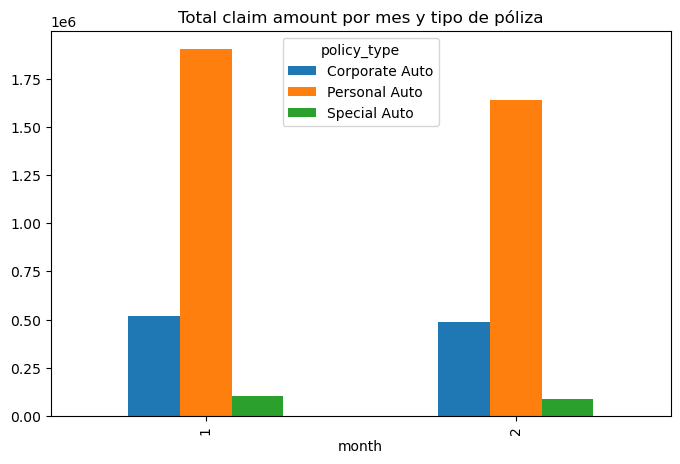

In [13]:
pivot_month_policy.plot(kind="bar", figsize=(8, 5), title="Total claim amount por mes y tipo de póliza")

1. You work at the marketing department and you want to know which sales channel brought the most sales in terms of total revenue. Using pivot, create a summary table showing the total revenue for each sales channel (branch, call center, web, and mail).
Round the total revenue to 2 decimal points.  Analyze the resulting table to draw insights.

2. Create a pivot table that shows the average customer lifetime value per gender and education level. Analyze the resulting table to draw insights.

## Bonus

You work at the customer service department and you want to know which months had the highest number of complaints by policy type category. Create a summary table showing the number of complaints by policy type and month.
Show it in a long format table.

*In data analysis, a long format table is a way of structuring data in which each observation or measurement is stored in a separate row of the table. The key characteristic of a long format table is that each column represents a single variable, and each row represents a single observation of that variable.*

*More information about long and wide format tables here: https://www.statology.org/long-vs-wide-data/*

In [14]:
complaints_long = (
    df.groupby(["policy_type", "month"])["number_of_open_complaints"]
    .sum()
    .round(0)
    .astype(int)
    .reset_index(name="total_complaints")
    .sort_values("total_complaints", ascending=False)
    .reset_index(drop=True)
)
complaints_long

,policy_type,month,total_complaints
0,Personal Auto,1,1728
1,Personal Auto,2,1454
2,Corporate Auto,1,443
3,Corporate Auto,2,385
4,Special Auto,2,95
5,Special Auto,1,87


In [15]:
complaints_long.loc[complaints_long.groupby("policy_type")["total_complaints"].idxmax()]

,policy_type,month,total_complaints
2,Corporate Auto,1,443
0,Personal Auto,1,1728
4,Special Auto,2,95


<Axes: title={'center': 'Quejas por mes y tipo de póliza'}, xlabel='month'>

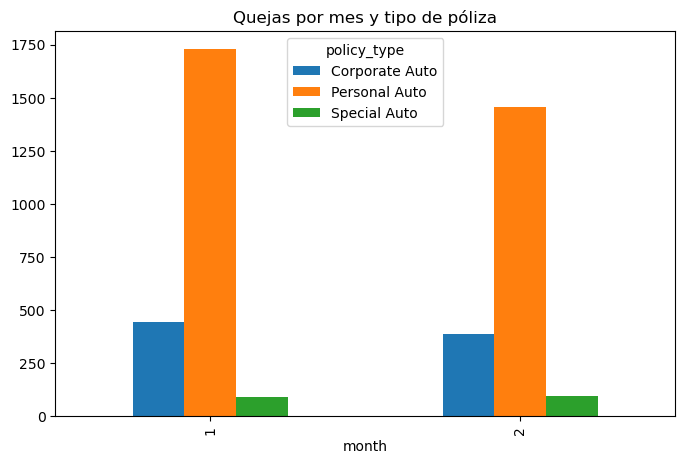

In [16]:
complaints_long.pivot(index="month", columns="policy_type", values="total_complaints").plot(
    kind="bar", figsize=(8, 5), title="Quejas por mes y tipo de póliza"
)